1) Implement inverse transform sampling for the exponential distribution. Verify by sampling 10,000 values and comparing the histogram to the true PDF.

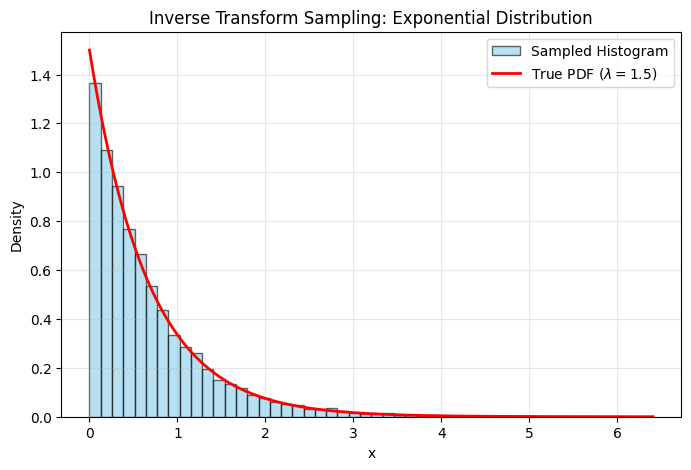

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parameters & Sample Generation
lambda_param = 1.5
n_samples = 10000

# Draw uniform samples U ~ Unif(0, 1) and apply the inverse CDF transform
u = np.random.uniform(0, 1, n_samples)
samples = -np.log(u) / lambda_param

# 2. Plot Histogram vs True PDF
plt.figure(figsize=(8, 5))

# Plot normalized histogram of generated samples
plt.hist(samples, bins=50, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Sampled Histogram')

# Plot true theoretical PDF: f(x) = lambda * exp(-lambda * x)
x = np.linspace(0, np.max(samples), 1000)
pdf = lambda_param * np.exp(-lambda_param * x)
plt.plot(x, pdf, 'r-', lw=2, label=f'True PDF ($\lambda={lambda_param}$)')

# Formatting
plt.title('Inverse Transform Sampling: Exponential Distribution')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

2) Build a joint distribution table for two loaded dice. Compute the marginal distributions and check whether the dice are independent.

In [2]:
import numpy as np
import pandas as pd

# 1. Define loaded probability distributions for Die 1 (X) and Die 2 (Y)
# Probabilities for faces [1, 2, 3, 4, 5, 6] (must sum to 1.0)
p_X = np.array([0.1, 0.1, 0.1, 0.2, 0.2, 0.3])  # Die 1 biased towards 4, 5, 6
p_Y = np.array([0.3, 0.2, 0.2, 0.1, 0.1, 0.1])  # Die 2 biased towards 1, 2, 3

# 2. Compute Joint Distribution Table under Independence assumption: P(X=i, Y=j) = P(X=i) * P(Y=j)
joint_matrix = np.outer(p_X, p_Y)

# Convert to Pandas DataFrame for readable table representation
outcomes = [1, 2, 3, 4, 5, 6]
joint_df = pd.DataFrame(joint_matrix, index=[f"X={i}" for i in outcomes], columns=[f"Y={j}" for j in outcomes])

# 3. Compute Marginal Distributions
marginal_X = joint_matrix.sum(axis=1)  # Row sums -> P(X)
marginal_Y = joint_matrix.sum(axis=0)  # Column sums -> P(Y)

# Add Marginals to DataFrame for display
joint_df_display = joint_df.copy()
joint_df_display['P(X)'] = marginal_X
joint_df_display.loc['P(Y)'] = np.append(marginal_Y, 1.0)

print("--- JOINT DISTRIBUTION TABLE & MARGINALS ---")
print(joint_df_display.round(4))
print("\n" + "="*50 + "\n")

# 4. Programmatic Independence Check: P(X=i, Y=j) == P(X=i) * P(Y=j) for all i, j
expected_joint = np.outer(marginal_X, marginal_Y)
is_independent = np.allclose(joint_matrix, expected_joint)

print("--- INDEPENDENCE VERIFICATION ---")
print(f"Computed Marginal P(X): {marginal_X.round(3)}")
print(f"Computed Marginal P(Y): {marginal_Y.round(3)}")
print(f"Are the two dice independent? -> {is_independent}")

--- JOINT DISTRIBUTION TABLE & MARGINALS ---
       Y=1   Y=2   Y=3   Y=4   Y=5   Y=6  P(X)
X=1   0.03  0.02  0.02  0.01  0.01  0.01   0.1
X=2   0.03  0.02  0.02  0.01  0.01  0.01   0.1
X=3   0.03  0.02  0.02  0.01  0.01  0.01   0.1
X=4   0.06  0.04  0.04  0.02  0.02  0.02   0.2
X=5   0.06  0.04  0.04  0.02  0.02  0.02   0.2
X=6   0.09  0.06  0.06  0.03  0.03  0.03   0.3
P(Y)  0.30  0.20  0.20  0.10  0.10  0.10   1.0


--- INDEPENDENCE VERIFICATION ---
Computed Marginal P(X): [0.1 0.1 0.1 0.2 0.2 0.3]
Computed Marginal P(Y): [0.3 0.2 0.2 0.1 0.1 0.1]
Are the two dice independent? -> True


3) Compute the cross-entropy loss for a 5-class classifier that outputs logits [2.0, 0.5, -1.0, 3.0, 0.1] when the correct class is index 3. Then verify your answer with PyTorch's nn.CrossEntropyLoss.

In [4]:
import torch
import torch.nn as nn

# Define inputs as 2D tensor (batch_size=1, num_classes=5)
logits = torch.tensor([[2.0, 0.5, -1.0, 3.0, 0.1]])
target = torch.tensor([3])

# Compute loss using PyTorch
criterion = nn.CrossEntropyLoss()
loss = criterion(logits, target)

print(f"PyTorch Loss: {loss.item():.6f}")

ModuleNotFoundError: No module named 'torch'